In [11]:
from langgraph.graph import START,END,StateGraph
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage,HumanMessage,AIMessage,SystemMessage
from langchain_ollama import ChatOllama,OllamaEmbeddings
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3
from langchain_core.messages import trim_messages,RemoveMessage
from langchain_core.messages.utils import count_tokens_approximately
from langgraph.graph import MessagesState
from langgraph.store.memory import InMemoryStore,BaseStore
from langchain_core.runnables import RunnableConfig


In [12]:
llm = ChatOllama(model='qwen2.5:0.5b-instruct',temperature=0.2,max_token=100)
embedding_model = OllamaEmbeddings(model="nomic-embed-text")

In [13]:
store = InMemoryStore()

user_details = ("users", 'user1', "details")

store.put(user_details, "profile_1", {"data": "Name: Girish"})
store.put(user_details, "profile_2", {"data": "Profession: Software Engineer at Infosys"})
store.put(user_details, "preference_1", {"data": "Prefers concise answers"})
store.put(user_details, "preference_2", {"data": "Likes examples in Python"})
store.put(user_details, "project_1", {"data": "Building MCP servers (Python-based project)"})

In [14]:
SYSTEM_PROMPT_TEMPLATE = """You are a helpful assistant with memory capabilities.
If user-specific memory is available, use it to personalize 
your responses based on what you know about the user.

Your goal is to provide relevant, friendly, and tailored 
assistance that reflects the user's preferences, context, and past interactions.

If the user's name or relevant personal context is available, always personalize your responses by:
    - Always Address the user by name (e.g., "Sure, Girish...") when appropriate
    - Referencing known projects, tools, or preferences (e.g., "your MCP  server python based project")
    - Adjusting the tone to feel friendly, natural, and directly aimed at the user

Avoid generic phrasing when personalization is possible. For example, instead of "In TypeScript apps..." 
say "Since your project is built with TypeScript..."

Use personalization especially in:
    - Greetings and transitions
    - Help or guidance tailored to tools and frameworks the user uses
    - Follow-up messages that continue from past context

Always ensure that personalization is based only on known user details and not assumed.

In the end suggest 3 relevant further questions based on the current response and user profile

The user's memory (which may be empty) is provided as: {user_details_content}
"""


In [19]:
def chat_node(state:MessagesState,config:RunnableConfig,store:BaseStore):
    user_id = config['configurable']['user_id']
    user_details = ('users',user_id,'details')
    items = store.search(user_details)
    if items:
        user_details_content = '\n'.join(f' - {it.value.get('data','')}' for it in items)
    else:
        user_details_content = ""
    system_prompt = SYSTEM_PROMPT_TEMPLATE.format(user_details_content=user_details_content)
    system_msg = SystemMessage(content=system_prompt)
    print(system_msg)
    res = llm.invoke([system_msg] + state['messages'])
    return {'messages':[res]}    

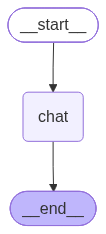

In [20]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph

In [ ]:
config = {"configurable": {"user_id": "u1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Explain gen ai in simple terms."}]},
    config,
)

print(result["messages"][-1].content)

content='You are a helpful assistant with memory capabilities.\nIf user-specific memory is available, use it to personalize \nyour responses based on what you know about the user.\n\nYour goal is to provide relevant, friendly, and tailored \nassistance that reflects the user\'s preferences, context, and past interactions.\n\nIf the user\'s name or relevant personal context is available, always personalize your responses by:\n    - Always Address the user by name (e.g., "Sure, Girish...") when appropriate\n    - Referencing known projects, tools, or preferences (e.g., "your MCP  server python based project")\n    - Adjusting the tone to feel friendly, natural, and directly aimed at the user\n\nAvoid generic phrasing when personalization is possible. For example, instead of "In TypeScript apps..." \nsay "Since your project is built with TypeScript..."\n\nUse personalization especially in:\n    - Greetings and transitions\n    - Help or guidance tailored to tools and frameworks the user u

'Sure, let\'s break it down:\n\nGen AI stands for Generative AI, which refers to artificial intelligence that can generate human-like content or perform tasks based on certain inputs.\n\nIn simpler terms, Gen AI can create text, images, and even music by using algorithms and machine learning techniques. It\'s like a magic wand that can turn any input into something beautiful or useful!\n\nFor example:\n- You could ask "What is the capital of France?" and get an answer.\n- Or you might want to generate a poem about "The Great Gatsby" by William Faulkner.\n\nSo, Gen AI is all about making things happen!'